# 03 · Kiểm định và baseline

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').exists():
    raise FileNotFoundError('Mở notebook từ thư mục dự án hoặc notebooks/.')
sys.path.insert(0, str(ROOT))
from scripts import final_study as study
from IPython.display import display
study.style()

In [2]:
metrics, oof = study.evaluate()
display(metrics)
print('Các model dùng đúng cùng symbol/decision_time/target. Đây là CV, không phải final test mới.')

Các model dùng đúng cùng symbol/decision_time/target. Đây là CV, không phải final test mới.


,model,rows,mae,mse,mse_ratio_to_zero,directional_accuracy,beats_zero_every_fold,independent_final_test,signal_approved
0,ridge,1878,0.006204,0.000095,0.994550,0.466986,False,False,False
1,xgboost_d3,1878,0.006181,0.000095,0.998255,0.512780,False,False,False
2,tcn_fixed6,1878,0.006289,0.000096,1.009102,0.518104,False,False,False
3,zero_return,1878,0.006170,0.000095,1.000000,0.532481,False,False,False
4,naive_ret4,1878,0.009430,0.000197,2.071623,0.495208,False,False,False


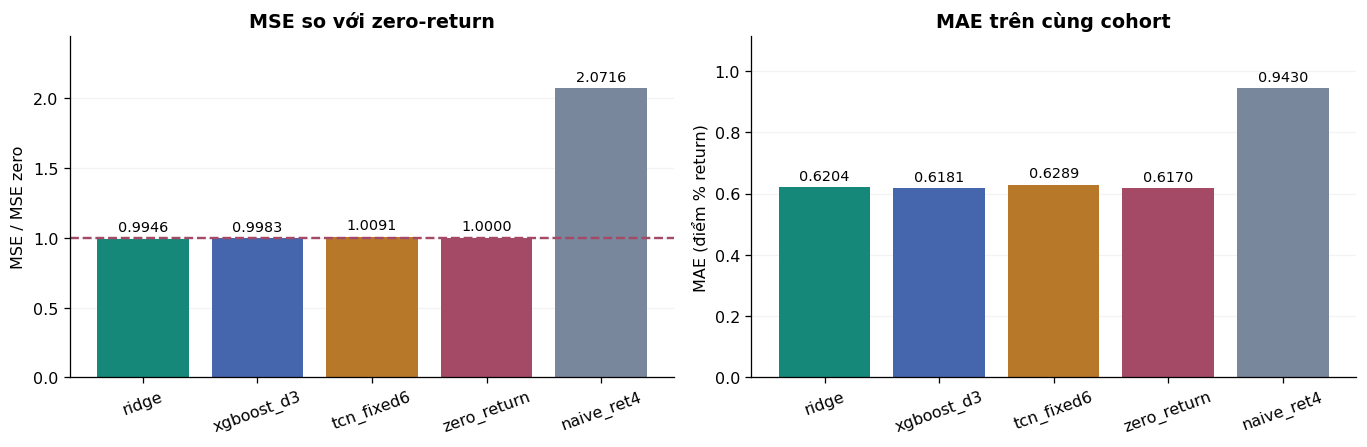

In [3]:
study.show(study.baseline_chart(metrics))

,model,fold,mse_ratio_to_zero
0,ridge,1,0.986099
1,ridge,2,1.022540
2,ridge,3,0.983575
3,xgboost_d3,1,1.010488
4,xgboost_d3,2,1.010154
5,xgboost_d3,3,0.983918
6,tcn_fixed6,1,0.971822
7,tcn_fixed6,2,1.054677
8,tcn_fixed6,3,1.005606
9,zero_return,1,1.000000


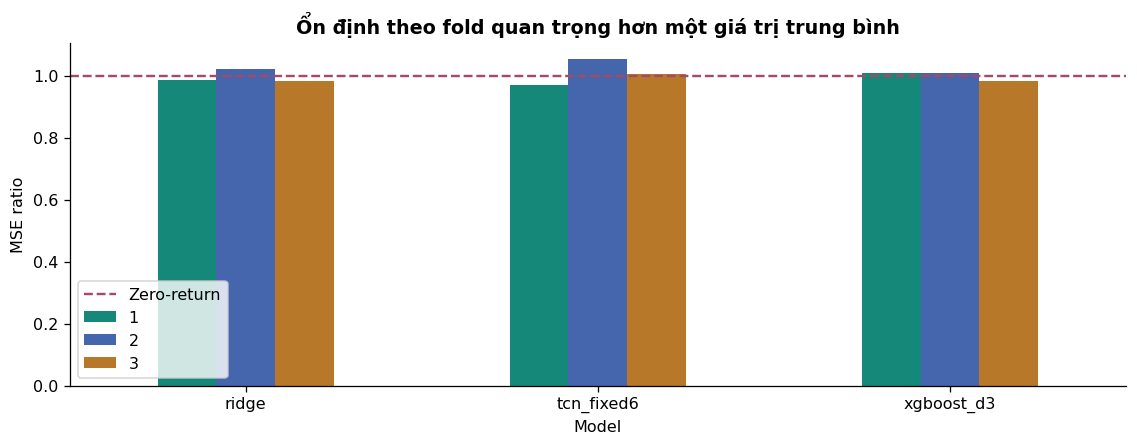

In [4]:
display(__import__('pandas').read_csv(study.REPORT / 'fold_metrics.csv'))
study.show(study.fold_chart())

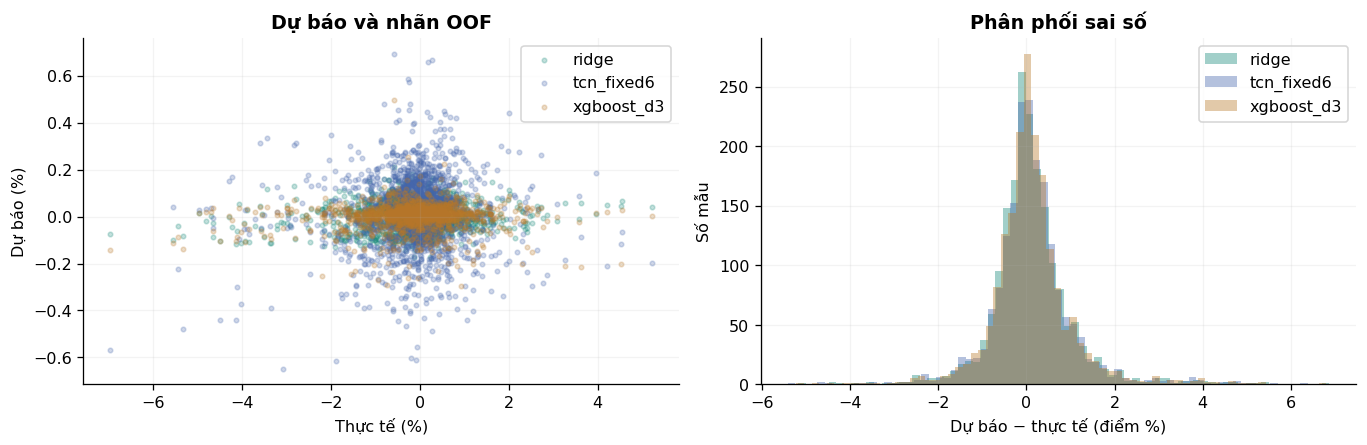

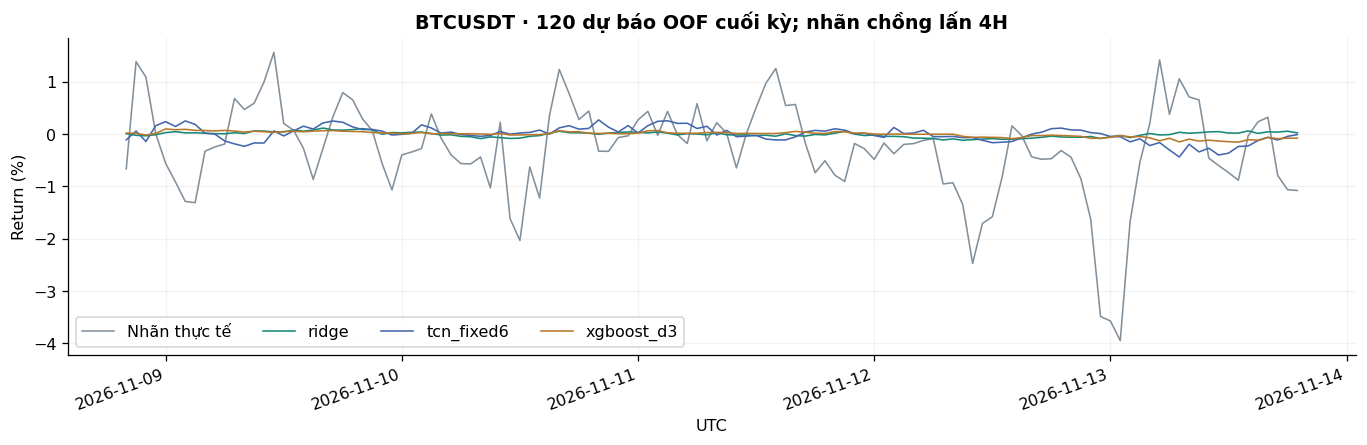

In [5]:
study.prediction_charts(oof)

Phí 10 bps + slippage 5 bps mỗi chiều; 10% vốn/vị thế. Ngưỡng 0,6% cố định.


,model,threshold,total_return,sharpe_hourly_estimate,max_drawdown,trades,win_rate,turnover,note
0,ridge,0.003,0.000000,0.000000,0.000000,0,0.000000,0.000000,Hourly Sharpe assumes sqrt(8760) scaling; seri...
1,ridge,0.006,0.000000,0.000000,0.000000,0,0.000000,0.000000,Hourly Sharpe assumes sqrt(8760) scaling; seri...
2,ridge,0.009,0.000000,0.000000,0.000000,0,0.000000,0.000000,Hourly Sharpe assumes sqrt(8760) scaling; seri...
3,xgboost_d3,0.003,-0.000437,-2.660133,-0.000660,1,0.000000,0.199126,Hourly Sharpe assumes sqrt(8760) scaling; seri...
4,xgboost_d3,0.006,0.000000,0.000000,0.000000,0,0.000000,0.000000,Hourly Sharpe assumes sqrt(8760) scaling; seri...
5,xgboost_d3,0.009,0.000000,0.000000,0.000000,0,0.000000,0.000000,Hourly Sharpe assumes sqrt(8760) scaling; seri...
6,tcn_fixed6,0.003,-0.004775,-5.169319,-0.005046,17,0.352941,3.383244,Hourly Sharpe assumes sqrt(8760) scaling; seri...
7,tcn_fixed6,0.006,-0.000506,-2.463288,-0.000828,3,0.000000,0.598808,Hourly Sharpe assumes sqrt(8760) scaling; seri...
8,tcn_fixed6,0.009,0.000000,0.000000,0.000000,0,0.000000,0.000000,Hourly Sharpe assumes sqrt(8760) scaling; seri...


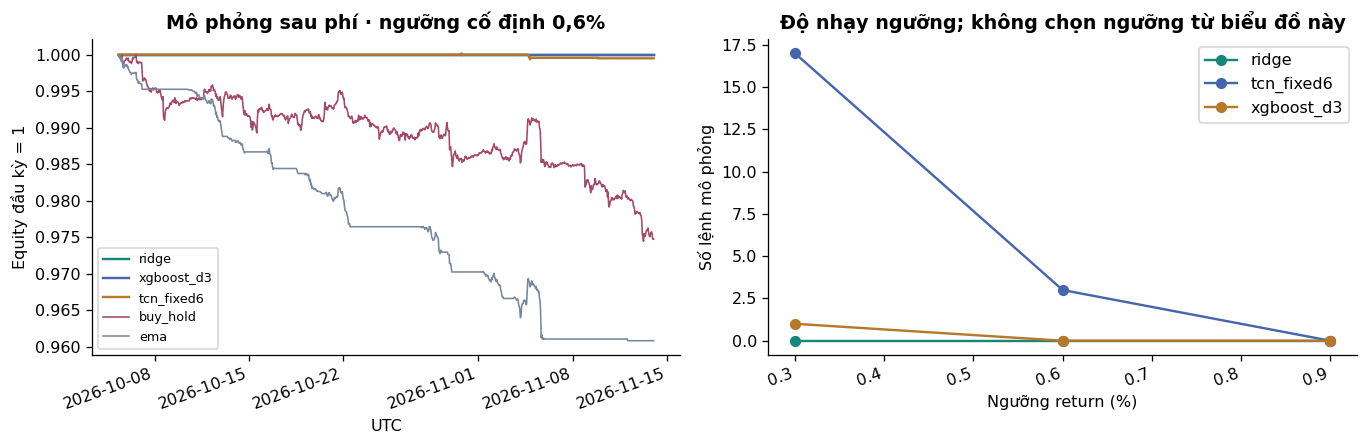

In [6]:
display(__import__('pandas').read_csv(study.REPORT / 'backtests.csv'))
study.show(study.strategy_charts())
print('Phí 10 bps + slippage 5 bps mỗi chiều; 10% vốn/vị thế. Ngưỡng 0,6% cố định.')

In [7]:
display(metrics[['model','beats_zero_every_fold','independent_final_test','signal_approved']])
assert not metrics.signal_approved.any()
print('Không mở khóa đầu tư chỉ vì một metric trung bình < 1. Cần cohort tương lai chưa dùng để quyết định.')

Không mở khóa đầu tư chỉ vì một metric trung bình < 1. Cần cohort tương lai chưa dùng để quyết định.


,model,beats_zero_every_fold,independent_final_test,signal_approved
0,ridge,False,False,False
1,xgboost_d3,False,False,False
2,tcn_fixed6,False,False,False
3,zero_return,False,False,False
4,naive_ret4,False,False,False
